# Sprawozdanie dotyczące sektora bankowego w latach 2010-2024

Opracowywane dane zostały pobrane ze strony KNFu. Dotyczą one struktury sektora bankowego - liczby banków, oddziałów i osób zatrudnionych w sektorze bankowym w tych latach. Analiza jest przeprowadzona w ujęciu rocznym.

Zacznę od pobrania i przygotowania dostępnych danych.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

dane = pd.read_csv("C:/Users/olako/OneDrive/Pulpit/bankowość/Dane_statystyczne.csv", delimiter=';', skiprows=1)
dane.Data = pd.to_datetime(dane['Data'])
dane.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 18 columns):
 #   Column                                                      Non-Null Count  Dtype         
---  ------                                                      --------------  -----         
 0   Data                                                        181 non-null    datetime64[ns]
 1   Sektor bankowy                                              181 non-null    int64         
 2   Liczba banków komercyjnych                                  181 non-null    int64         
 3   Liczba oddziałów                                            181 non-null    int64         
 4   Liczba banków spółdzielczych                                181 non-null    int64         
 5   Liczba oddziałów.1                                          181 non-null    int64         
 6   W kraju                                                     181 non-null    int64         
 7   Za granicą                

Na początku zamieniłam typ danych w kolumnach tak, żeby kolumna "Data" korzystała z typu datetime, a pozostałe kolumny przyjmowały wartości typu integer. Widać też, że wśród danych nie ma wartości Null - nie musimy się nimi przejmować przy dalszej obróbce danych.

Część kolumn jest opisana w sposób nieprecyzyjny. Kolumny 1-4 dotyczą liczby różnego rodzaju banków. Kolumna "Sektor bankowy" sumuje wszystkie typy banków (komercyjne, spółdzielcze i osobne oddziały). 

Kolumny 5-13 dotyczą łącznej sieci bankowej wszystkich banków. Kolumna "Liczba oddziałów.1" sumuje wszystkie oddziały, "Liczba przedstawicielstw" sumuje przedstawicielstwa, a "Liczba filii, ekspozytur i innych placówek obsługi klienta" pozostałe placówki obsługi klienta. Każde z nich jest jeszcze podzielone na krajowe i zagraniczne.

Kolumny 14-17 dotyczą liczby osób zatrudnionych w sektorze bankowym z podziałem na zatrudnionych w centrali, w kraju i za granicą.

W tej analizie będę skupiać się przede wszystkim na liczbie wszystkich banków, oddziałów i zatrudnionych. Następnie przeanalizuje dodatkowo każdy z sektorów z osobna. Do tej części analizy będę potrzebowała sumy wszystkich placówek z łącznej sieci bankowej. Dlatego poniżej tworzę dodatkowe kolumny zbierające całą sieć bankową oraz placówki krajowe i zagraniczne.

In [ ]:
dane['Sieć banków'] = dane[['Liczba oddziałów.1', 'Liczba filii, ekspozytur i innych placówek obsługi klienta', 'Liczba przedstawicielstw']].sum(axis=1)
dane['W kraju_S'] = dane[['W kraju', 'W kraju.1', 'W kraju.2']].sum(axis=1)
dane['Za granicą_S'] = dane[['Za granicą', 'Za granicą.1', 'Za granicą.2']].sum(axis=1)

Poniżej widać wycinek najważniejszych kolumn z danymi.

In [ ]:
dane[['Data', 'Sektor bankowy', 'Liczba oddziałów.1', 'Liczba zatrudnionych', 'Sieć banków']]

,Data,Sektor bankowy,Liczba oddziałów.1,Liczba zatrudnionych,Sieć banków
0,2009-12-31,643,6507,175249,13910
1,2010-01-31,643,6837,173966,13989
2,2010-02-28,644,6814,174258,14068
3,2010-03-31,645,6893,175497,13966
4,2010-04-30,645,6894,176705,14084
...,...,...,...,...,...
176,2024-08-31,552,4886,146193,9865
177,2024-09-30,552,4882,146326,9843
178,2024-10-31,551,4878,146304,9791
179,2024-11-30,551,4940,146589,9720


Kolejnym ważnym elementem obróbki danych jest wyłączenie z analizy wartości odstających. Przyjęłam, że pominę te miesiące, w których wpisane dane można uznać za błędne. Okazuje się, że jedynie w dwóch wierszach z wysokim prawdopodobieństwem zostały wpisane niepoprawne dane. W dalszej części analizy korzystam jedynie z pozostałych danych.

In [ ]:
z_score = dane.sub(dane.mean()).div(dane.std())
outliers = (z_score.abs() > 3)

dane_no_outliers = dane[~outliers.any(axis=1)]
print(dane_no_outliers)

dane = dane_no_outliers

          Data  Sektor bankowy  Liczba banków komercyjnych  Liczba oddziałów  \
0   2009-12-31             643                          49                18   
1   2010-01-31             643                          48                19   
2   2010-02-28             644                          48                20   
3   2010-03-31             645                          49                20   
4   2010-04-30             645                          49                20   
..         ...             ...                         ...               ...   
176 2024-08-31             552                          29                33   
177 2024-09-30             552                          29                33   
178 2024-10-31             551                          29                33   
179 2024-11-30             551                          29                33   
180 2024-12-31             551                          29                33   

     Liczba banków spółdzielczych  Licz

C:\Users\olako\AppData\Local\Temp\ipykernel_1312\1388053890.py:1: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  z_score = dane.sub(dane.mean()).div(dane.std())


Zauważmy dodatkowo, że z 2009 roku mamy jedynie dane z grudnia. Ponieważ dane będą przedstawiane w ujęciu rocznym, może to zaburzyć obraz sytuacji. Dlatego pominę w analizie rok 2009.

Przyjrzyjmy się najpierw rocznym średnim wartościom dla najistotniejszych wartości - liczby wszystkich banków, oddziałów i osób zatrudnionych. Poniżej znajduje się zarówno tabela z danymi, jak i wykresy pokazujące tendencje na przedziale 15 lat.

In [ ]:
dane['Rok']=dane.Data.dt.year
dane.loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').agg({'Sektor bankowy': ['mean'], "Liczba oddziałów.1": ['mean'], "Liczba zatrudnionych": ['mean']}).round(0)

,Sektor bankowy,Liczba oddziałów.1,Liczba zatrudnionych
,mean,mean,mean
Rok,,,
2010,645.0,6887.0,176224.0
2011,644.0,7058.0,177523.0
2012,642.0,7206.0,175954.0
2013,642.0,7396.0,174256.0
2014,634.0,7311.0,173042.0
2015,628.0,7312.0,171314.0
2016,623.0,7258.0,170296.0
2017,619.0,6816.0,166378.0


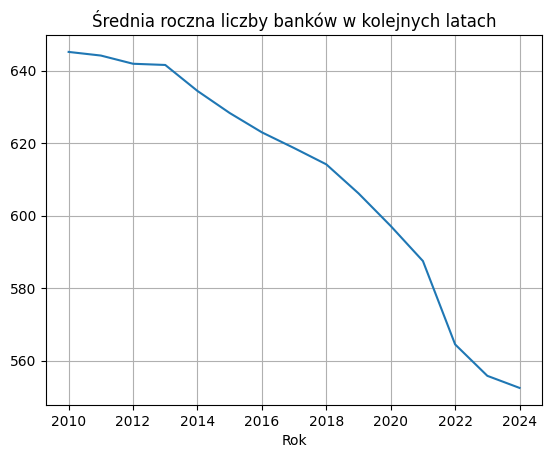

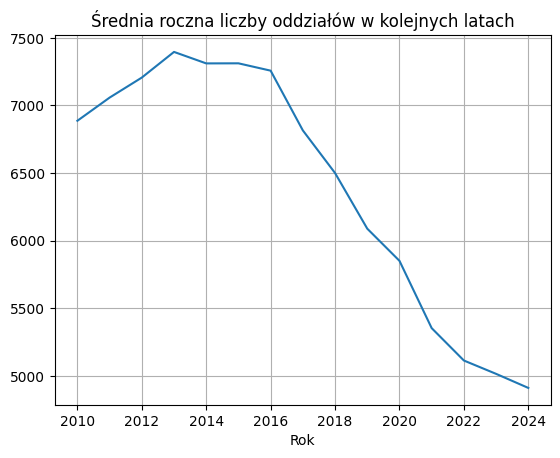

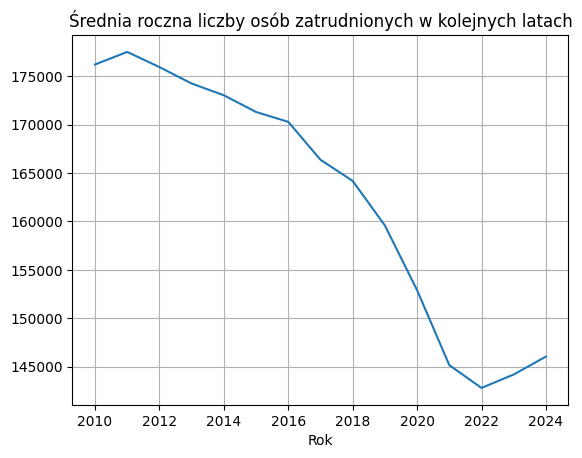

In [ ]:
dane.loc[(dane.Data >= '2010-01-01'), :].groupby("Rok")["Sektor bankowy"].mean().plot(grid=True, title='Średnia roczna liczby banków w kolejnych latach')
plt.show()
dane.loc[(dane.Data >= '2010-01-01'), :].groupby("Rok")["Liczba oddziałów.1"].mean().plot(grid=True, title='Średnia roczna liczby oddziałów w kolejnych latach')
plt.show()
dane.loc[(dane.Data >= '2010-01-01'), :].groupby("Rok")["Liczba zatrudnionych"].mean().plot(grid=True, title='Średnia roczna liczby osób zatrudnionych w kolejnych latach')
plt.show()

Przy analizie powyższych wykresów warto zwrócić uwagę na skale osi Y. Celowo obejmuje ona określony przedział, żeby dobrze zobrazować tendencje, ale jednocześnie wyolbrzymia notowany spadek. Dla porównania notowany spadek średnich rocznych między 2010 a 2024 rokiem wynosi odpowiednio około 14% dla liczby banków, 29% dla liczby oddziałów i 17% dla liczby osób zatrudnionych.

Porównując między sobą wykresy, można zwrócić uwagę na parę zależności. Początkowy wzrost liczby oddziałów między 2010 a 2013 rokiem odpowiada mniejszej tendencji spadkowej liczby wszystkich banków. Spadek liczby banków z 2013 roku odpowiada zatrzymaniu się tendencji rosnącej liczby oddziałów. Zaczyna ona stopniowo spadać, a w 2016 roku znacząco przyspiesza. Być może konsekwencją tendencji spadkowej w liczbie wszystkich banków rozpoczątej w 2013 roku jest nagły spadek liczby oddziałów w 2016 roku. Równolegle w 2016 roku odnotowano zwiększenie tendencji spadkowej w liczbie osób zatrudnionych w sektorze bankowym. Z kolei w roku 2018 zachodzi równoczesne zwiększenie tempa spadku liczby banków oraz liczby zatrudnionych. W 2020 roku tendencja spadkowa w liczbie oddziałów zwiększa się raz jeszcze, a rok później zwiększenie spadku widać także na średniej liczbie banków. Jednocześnie w 2021 zmniejsza się spadek liczby zatrudnionych. Na sytuację z tego okresu mogła wpływać pandemia. Od 2022 roku sytuacja wydaje się stabilizować. Odnotowano zmniejszenie tendencji spadkowych zarówno w liczbie banków, jak  i w liczbie wszystkich oddziałów. Zwiększyła się także liczba osób zatrudnionych przez banki.

Przyjrzyjmy się jeszcze tendencjom na różnych podgrupach danych. Zacznę od omówienia wykresu liczby banków.

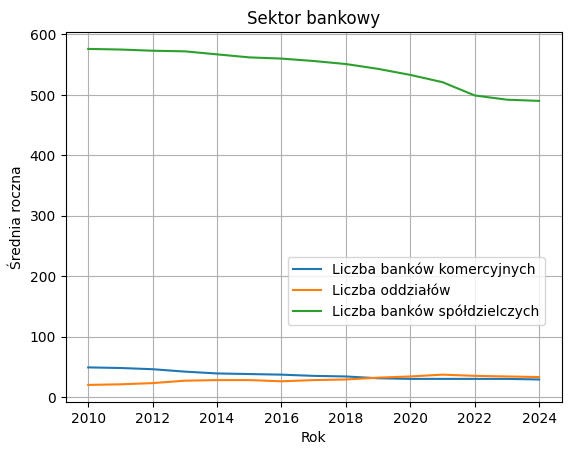

In [ ]:
dane[['Rok', 'Liczba banków komercyjnych', 'Liczba oddziałów', 'Liczba banków spółdzielczych']].loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').mean().round(0).plot(grid=True, title='Sektor bankowy', ylabel='Średnia roczna')
plt.legend(['Liczba banków komercyjnych', 'Liczba oddziałów', 'Liczba banków spółdzielczych'], loc='center right', bbox_to_anchor=(0.98, 0.3))
plt.show()

Pierwszą obserwacją jest znacząca przewaga liczby banków spółdzielczych wśród wszystkich banków. Można także zauważyć, że na przedziale całych 15 lat liczba banków komercyjnych ma stale tendencje spadkową. Od 2010 roku do 2019 roku liczba banków komercyjnych była więszka niż liczba osobnych oddziałów. Jednak w 2019 roku sytuacja uległa zmianie i liczba oddziałów uzyskała nieznaczną przewagę. Są to jednak wartości porównywalnej wielkości.

Poniżej przedstawiam wykres dotyczący średniej rocznej liczby poszczególnych typów placówek z sieci bankowej z podziałem na oddziały, przedstawicielstwa oraz filie, ekspozytury i inne placówki obsługi klienta.

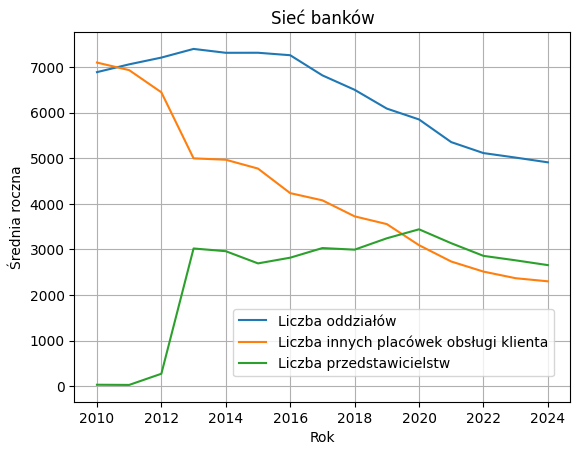

In [ ]:
dane[['Rok', 'Liczba oddziałów.1', 'Liczba filii, ekspozytur i innych placówek obsługi klienta', 'Liczba przedstawicielstw']].loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').mean().round(0).plot(grid=True, title='Sieć banków', ylabel='Średnia roczna')
plt.legend(['Liczba oddziałów','Liczba innych placówek obsługi klienta', 'Liczba przedstawicielstw'], loc='lower right', bbox_to_anchor=(0.98, 0.05))
plt.show()

Wykres ten przedstawia pewne ciekawe zależności. Warto zauważyć, że liczba przedstawicielstw przed 2013 rokiem była niemal marginalna. W 2013 roku sytuacja nagle uległa zmianie i w kolejnych latach średnia roczna liczba przedstawicielstw utrzymuje się w przedziale 2500-3500. Liczba wszystkich oddziałów początkowo rośnie i od 2013 roku stopniowo zaczyna maleć. Od 2016 roku spadek ten znacząco się powiększył.
Liczba pozostałych placówek obsługi klienta zachowuje tendencję malejącą na całym przedziale. Największy spadek jest zauważalny właśnie między 2012 a 2013 rokiem i prawdopodobnie jest on związany z nagłym wzrostem liczby przedstawicielstw. Od 2020 roku średnia roczna liczba przedstawicielstw przekracza liczbę innych placówek obsługi klienta. Od 2020 roku wszystkie typy placówek zachowują podobną tendencje malejącą, z łagodniejszym spadkiem po 2021 roku.

Źródłowe dane dotyczące placówek sieci bankowej były także dzielone na oddziały krajowe i zagraniczne. Zobaczmy ich średnie roczne w tabeli.

In [ ]:
dane.loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').agg({'Sieć banków': ['mean'], "W kraju_S": ['mean'], "Za granicą_S": ['mean']}).round(0)

,Sieć banków,W kraju_S,Za granicą_S
,mean,mean,mean
Rok,,,
2010,14018.0,13978.0,41.0
2011,14021.0,13981.0,40.0
2012,13927.0,13888.0,40.0
2013,15415.0,15376.0,39.0
2014,15240.0,15204.0,36.0
2015,14780.0,14743.0,38.0
2016,14313.0,14273.0,40.0
2017,13923.0,13879.0,44.0


Przeważająca większość placówek znajduje się w kraju, jednak warto zwrócić uwagę, że ma przestrzeni 15 lat liczba placówek zagranicznych wzrosła ponad dwukrotnie. Za moment przełomowy można uznać 2018 rok. W tym samym roku odnotowano znaczny wzrost w liczbie przedstawicielstw. Można zatem przypuszczać, że przynajmniej częściowo wzrost ten jest spowodowany wzrostem przedstawicielstw zagranicznych.

Przyjrzyjmy się jeszcze średniej rocznej liczbie osób zatrudnionych z podziałem na zatrudnionych w centrali, w kraju i za granicą. Ponieważ w tym przypadku liczba osób zatrudnionych za granicą jest także nieznaczna, przedstawię te dane dodatkowo w tabeli.

     Liczba zatrudnionych W centrali W kraju.3 Za granicą.3
                     mean       mean      mean         mean
Rok                                                        
2010             176224.0    69682.0  106411.0        130.0
2011             177523.0    71556.0  105828.0        139.0
2012             175954.0    72342.0  103464.0        148.0
2013             174256.0    72417.0  101618.0        220.0
2014             173042.0    72297.0  100519.0        225.0
2015             171314.0    73558.0   97507.0        249.0
2016             170296.0    76423.0   93575.0        298.0
2017             166378.0    76985.0   89067.0        326.0
2018             164187.0    78581.0   85175.0        431.0
2019             159584.0    80265.0   78797.0        523.0
2020             152891.0    79411.0   72895.0        585.0
2021             145149.0    79620.0   64965.0        564.0
2022             142793.0    81196.0   61051.0        546.0
2023             144180.0    85187.0   5

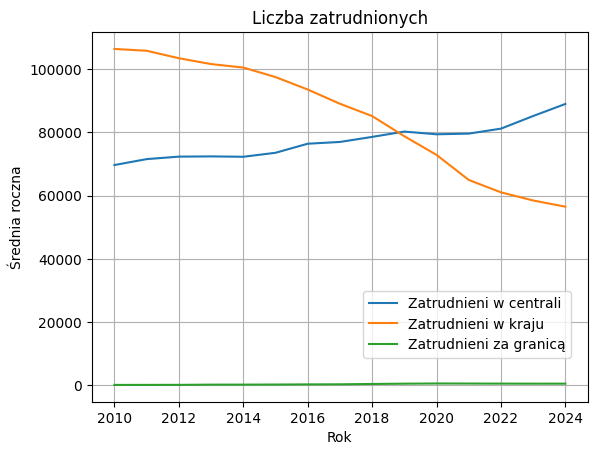

In [ ]:
print(dane.loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').agg({'Liczba zatrudnionych': ['mean'], "W centrali": ['mean'], "W kraju.3": ['mean'], "Za granicą.3": ['mean']}).round(0))

dane[['Rok', 'W centrali', 'W kraju.3', 'Za granicą.3']].loc[(dane.Data >= '2010-01-01'), :].groupby('Rok').mean().round(0).plot(grid=True, title='Liczba zatrudnionych', ylabel='Średnia roczna')
plt.legend(['Zatrudnieni w centrali', 'Zatrudnieni w kraju', 'Zatrudnieni za granicą'], loc='lower right', bbox_to_anchor=(0.98, 0.1))
plt.show()

Na podstawie tabeli można zauważyć, że wzrost rocznej średniej liczby osób zatrudnionych za granicą wzrósł ponad czterokrotnie w przeciągu ostatnich 15 lat. Łączy się to z obserwowaną tendencją w omówionej wyżej sieci bankowej. Liczba ta do 2020 roku stale wzrastała, jednak między 2020 a 2023 rokiem lekko spadła, jednak aktualnie trzyma się na podobnym poziomie.
Pozostałe miejsca zatrudnienia zachowują stale podobne tendencje. Liczba osób zatrudnionych w centrali rośnie na całym przedziale, a osób  zatrudnionych w kraju na całym przedziale maleje. Do 2019 roku osób zatrudnionych w kraju było więcej niż zatrudnionych w centrali, później sytuacja się odwróciła. Między 2018 a 2021 roku spadek osób zatrudnionych w kraju był większy. Mogło być to spowodowane pandemią. Od 2021 roku sytuacja zaczęła się stabilizować i utrzymuje się w okolicach 60 tys. osób zatrudnionych rocznie. Jest to duża zmiana względem początkowej liczby z 2010 roku przekraczającej 100 tys. Liczba osób zatrudnionych w centrali od 2022 roku zachowuje największą tendencję wzrostową względem ostatnich 15 lat. W 2024 roku średnia wynosiła niemal 90 tys. osób.